In [1]:
import numpy as np
from sklearn.datasets import make_blobs,make_circles,make_classification
import matplotlib.pyplot as plt

In [2]:
# X,y = make_blobs(500,2,centers=2)
X,y = make_classification(1000,2,n_informative=2,n_redundant=0,random_state=42)

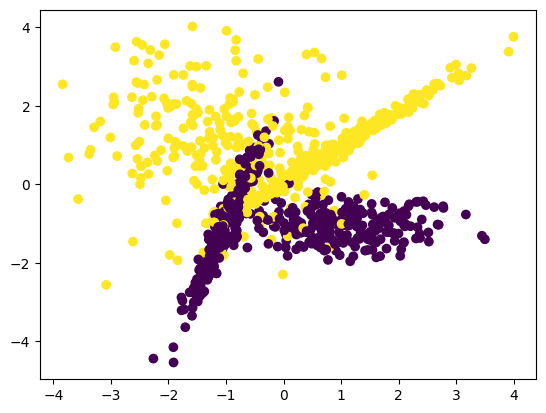

In [3]:
plt.scatter(X[:,0],X[:,1],c=y)

In [4]:
class NN:
    def __init__(self,input_dim = 2,hidden_layers = None,output_dim=1):
        self.weights = []
        self.bias = []

        self.weights.append(np.random.normal(scale = np.sqrt(6/(input_dim+hidden_layers[0])),size=(input_dim,hidden_layers[0])))
        for i in range(len(hidden_layers)-1):
            self.weights.append(np.random.normal(scale = np.sqrt(6/(hidden_layers[i]+hidden_layers[i+1])),size=(hidden_layers[i],hidden_layers[i+1])))
        self.weights.append(np.random.normal(scale = np.sqrt(6/(hidden_layers[-1]+output_dim)),size=(hidden_layers[-1],output_dim)))


        for i in range(len(hidden_layers)):
            self.bias.append(np.zeros(shape = hidden_layers[i]))

        self.bias.append(np.zeros(shape=output_dim))
        
    
    def activation(self,Z):
        return 1/(1+np.exp(-Z))
    
    def forwardProp(self,X):
        self.actvs = [X]

        for i in range(len(self.weights)):
            z = self.actvs[-1]@self.weights[i]+self.bias[i]
            self.actvs.append(self.activation(z))

        return self.actvs[-1]

    def loss(self,y,ypred):
        return -np.sum(y*np.log2(ypred)+(1-y)*np.log2(1-ypred))

    def derA(self,a):
        return a*(1-a)
        
    def backProp(self,X,y,lr=0.001,epochs=100):
        for e in range(epochs):
            ypred = self.forwardProp(X)
            delta = [ypred-y]
            grad = [self.actvs[-2].T@delta[-1]]

            for i in range(len(self.weights)-2,-1,-1):
                delta.append((delta[-1]@self.weights[i+1].T)*self.derA(self.actvs[i+1]))
                grad.append(self.actvs[i].T@delta[-1])

            wn = len(self.weights)-1
            for i in range(len(self.weights)):
                self.weights[i] = self.weights[i] - lr*grad[wn]
                self.bias[i] = self.bias[i] - lr*np.sum(delta[wn],axis = 0)
                wn -= 1

    def predict(self,X):
        ypred = self.forwardProp(X).reshape(-1)
        ypred[ypred < 0.5] = 0
        ypred[ypred >= 0.5] = 1
        return ypred

In [5]:
clf = NN(2,[4,2],1)

In [6]:
clf.weights

[array([[-0.47278953, -0.3173918 ,  1.10098997, -0.02116226],
        [-0.60285541, -0.28289763, -0.98900229, -0.10916135]]),
 array([[ 0.84590974,  0.44173984],
        [-0.01977817,  0.10648969],
        [-0.45742847, -2.36004619],
        [-2.56244198, -1.07154093]]),
 array([[-0.0938064 ],
        [ 0.32474678]])]

In [7]:
clf.bias

[array([0., 0., 0., 0.]), array([0., 0.]), array([0.])]

In [8]:
clf.forwardProp(X[:5])

array([[0.51358126],
       [0.50757313],
       [0.50781527],
       [0.52885744],
       [0.50774599]])

In [9]:
clf.actvs

[array([[-0.99910178, -0.66386   ],
        [ 1.24668618,  1.15359685],
        [ 0.96277683,  0.85939747],
        [-2.95744095,  2.03364529],
        [ 1.14116527,  1.05944863]]),
 array([[0.70528152, 0.62361277, 0.39092112, 0.5233857 ],
        [0.216722  , 0.32694441, 0.55766207, 0.46199572],
        [0.27422657, 0.36616631, 0.55232313, 0.4714841 ],
        [0.5429571 , 0.58985212, 0.00513058, 0.46023185],
        [0.23537144, 0.34031024, 0.55196527, 0.46510669]]),
 array([[0.28177108, 0.24871791],
        [0.2206183 , 0.15701542],
        [0.22512077, 0.16129922],
        [0.32430929, 0.44952088],
        [0.22236774, 0.15965035]]),
 array([[0.51358126],
        [0.50757313],
        [0.50781527],
        [0.52885744],
        [0.50774599]])]

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [11]:
x_train,x_test,y_train,y_test = train_test_split(X,y,train_size=0.8)

scale = StandardScaler()
x_train = scale.fit_transform(x_train)
x_test = scale.transform(x_test)

In [12]:
clf = NN(x_train.shape[1],[4,2,3],1)
clf.backProp(x_train,y_train.reshape((-1,1)),lr=0.001,epochs=1000)

In [13]:
clf.weights

[array([[ 0.12641533, -0.56575141, -0.98821328, -1.34140608],
        [ 1.81527169,  0.23311663,  1.283823  , -2.0074585 ]]),
 array([[ 0.98278308, -1.64707951],
        [ 0.51680683, -1.12999088],
        [ 1.12294064, -2.34495557],
        [ 0.20803861,  2.50347705]]),
 array([[-1.29287274,  1.19385359,  0.58395657],
        [ 2.60525022, -3.73612822, -3.5801304 ]]),
 array([[-2.96588157],
        [ 4.54533618],
        [ 3.92469012]])]

In [14]:
clf.bias

[array([-0.48603579,  0.06116627,  1.63702786,  1.7090852 ]),
 array([-0.10786888,  0.68033898]),
 array([0.09293489, 0.62252097, 0.85801071]),
 array([-2.42815268])]

In [15]:
np.mean(y_train == clf.predict(x_train))

np.float64(0.86625)

In [16]:
np.mean(y_test == clf.predict(x_test))

np.float64(0.875)